In [ ]:
if (!requireNamespace("caret", quietly = TRUE))
    install.packages("caret")
library(caret)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘proxy’, ‘iterators’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘sparsevctrs’, ‘timeDate’, ‘e1071’, ‘foreach’, ‘ModelMetrics’, ‘plyr’, ‘pROC’, ‘recipes’, ‘reshape2’


Loading required package: ggplot2

Loading required package: lattice



In [ ]:
df0 <- read.csv("jkp_us_selected_factors_long_short.csv")
df0$date <- as.Date(df0$date)
str(df0)
summary(df0)

'data.frame':	1200 obs. of  8 variables:
 $ date         : Date, format: "1926-01-31" "1926-02-28" ...
 $ Value        : num  NA NA NA NA NA NA NA NA NA NA ...
 $ Momentum     : num  NA NA NA NA NA NA NA NA NA NA ...
 $ Size         : num  0.02621 -0.02654 -0.04991 0.00268 -0.00696 ...
 $ Quality      : num  NA NA NA NA NA NA NA NA NA NA ...
 $ Low.Beta     : num  NA NA NA NA NA NA NA NA NA NA ...
 $ Profitability: num  NA NA NA NA NA NA NA NA NA NA ...
 $ Investment   : num  NA NA NA NA NA NA NA NA NA NA ...


      date                Value               Momentum        
 Min.   :1926-01-31   Min.   :-2.930e-01   Min.   :-0.589111  
 1st Qu.:1951-01-23   1st Qu.:-1.517e-02   1st Qu.:-0.009319  
 Median :1976-01-15   Median :-1.218e-05   Median : 0.008182  
 Mean   :1976-01-14   Mean   : 2.181e-03   Mean   : 0.006009  
 3rd Qu.:2001-01-07   3rd Qu.: 1.728e-02   3rd Qu.: 0.027226  
 Max.   :2025-12-31   Max.   : 2.059e-01   Max.   : 0.270445  
                      NAs    :298          NAs    :12         
      Size              Quality             Low.Beta         
 Min.   :-0.103418   Min.   :-0.113890   Min.   :-0.5937405  
 1st Qu.:-0.017566   1st Qu.:-0.007458   1st Qu.:-0.0263792  
 Median :-0.000885   Median : 0.003046   Median : 0.0004273  
 Mean   : 0.001834   Mean   : 0.002898   Mean   :-0.0008322  
 3rd Qu.: 0.015654   3rd Qu.: 0.013662   3rd Qu.: 0.0270078  
 Max.   : 0.543145   Max.   : 0.095467   Max.   : 0.2085567  
                     NAs    :358         NAs    :31          


In [ ]:
make_features <- function(df0, factor_name) {
  d <- data.frame(date = df0$date, ret = df0[[factor_name]])
  d <- d[!is.na(d$ret), ]
  n <- nrow(d)
  roll_sum <- as.numeric(stats::filter(d$ret,rep(1,12), sides = 1))
  roll_sd <- sapply(1:n, function(i) if (i < 12) NA else sd(d$ret[(i-11):i]))
  d$lag1 <- c(NA, d$ret[-n])
  d$mom12 <- c(NA, roll_sum[-n])
  d$vol12 <- c(NA, roll_sd[-n])
  na.omit(d)}

fac <- make_features(df0, "Value")
head(fac)
dim(fac)

,date,ret,lag1,mom12,vol12
,<date>,<dbl>,<dbl>,<dbl>,<dbl>
311,1951-11-30,-0.0041265219,0.0248661745,0.18754483,0.02352523
312,1951-12-31,-0.0311444387,-0.0041265219,0.13196060,0.02118509
313,1952-01-31,0.0122770442,-0.0311444387,0.05532681,0.02139165
314,1952-02-29,0.0127759199,0.0122770442,0.05234466,0.02127369
315,1952-03-31,0.0003758795,0.0127759199,0.08051663,0.02043291
316,1952-04-30,0.0045017622,0.0003758795,0.06320234,0.02019700


[1] 890   5

In [ ]:
trn <- subset(fac, date <= as.Date("1989-12-31"))
val <- subset(fac, date > as.Date("1989-12-31") & date <= as.Date("2004-12-31"))
tst <- subset(fac, date > as.Date("2004-12-31"))
trnval <- rbind(trn, val)
c(train = nrow(trn), validation = nrow(val), test = nrow(tst))

train validation       test 
       458        180        252

In [ ]:
ctrl <- trainControl(method = "cv",
                     index = list(fold1 = 1:nrow(trn)),
                     indexOut = list(fold1 = (nrow(trn) + 1):nrow(trnval)))
ks <- c(1,5,10,25,50,100,200)
mod_searched <- train(ret~lag1 + mom12 + vol12,
                      data = trnval,
                      method = "knn",
                      trControl = ctrl,
                      preProcess = c("center", "scale"),
                      tuneGrid = expand.grid(k = ks),
                      metric = "RMSE")
mod_searched
mod_searched$bestTune

k-Nearest Neighbors 

638 samples
  3 predictor

Pre-processing: centered (3), scaled (3) 
Resampling: Cross-Validated (10 fold) 
Summary of sample sizes: 458 
Resampling results across tuning parameters:

  k    RMSE        Rsquared    MAE       
    1  0.05467981  0.03984619  0.03738770
    5  0.04965731  0.02101467  0.03087937
   10  0.04874435  0.02422993  0.02995373
   25  0.04868041  0.02423009  0.02973463
   50  0.04856947  0.03354289  0.02943933
  100  0.04842392  0.06100598  0.02943019
  200  0.04879994  0.04656336  0.02960998

RMSE was used to select the optimal model using the smallest value.
The final value used for the model was k = 100.

,k
,<dbl>
6,100


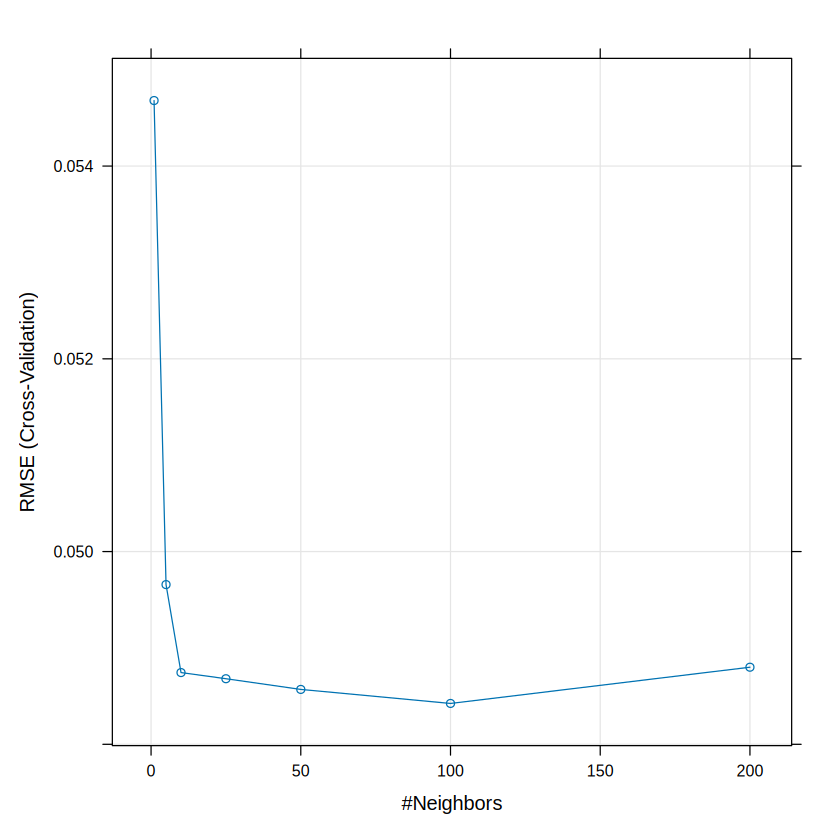

In [ ]:
plot(mod_searched)

In [ ]:
pred <- predict(mod_searched, newdata = tst)
bench <- mean(trnval$ret)

oos_r2 <- 1 - sum((tst$ret - pred)^2) / sum((tst$ret - bench)^2)
hit_rate <- mean(sign(pred) == sign(tst$ret))
timed <- ifelse(pred > 0, tst$ret, 0)
sharpe <- function(r) mean (r) / sd(r) * sqrt(12)

cat("Best K:", mod_searched$bestTune$k, "\n")
cat("Out-of-Sample (OoS) R2:", round(100 * oos_r2, 2), "%\n")
cat("Direction Hit Rate:", round(100 * hit_rate, 1), "%\n")
cat("Sharpe Ratio, always hold:", round(sharpe(tst$ret), 2), "\n")
cat("Sharpe Ratio, KNN-timed:", round(sharpe(timed), 2), "\n")

Best K: 100 
Out-of-Sample (OoS) R2: 2.44 %
Direction Hit Rate: 51.2 %
Sharpe Ratio, always hold: -0.06 
Sharpe Ratio, KNN-timed: 0.1 


In [ ]:
test_r2 <- sapply(ks, function(k) {
  m <- train(ret ~ lag1 + mom12 + vol12, data = trnval, method = "knn",
    trControl = trainControl(method = "none"),
    preProcess = c("center", "scale"), tuneGrid = data.frame(k = k))
  p <- predict(m, newdata = tst)
  1 - sum((tst$ret - p)^2) / sum((tst$ret - bench)^2)})
data.frame(k = ks, oos_r2_pct = round(100*test_r2, 2))

k,oos_r2_pct
<dbl>,<dbl>
1,-113.74
5,-32.22
10,-12.75
25,-1.33
50,2.39
100,2.44
200,3.53


In [ ]:
run_factor <- function(factor_name) {
  fac <- make_features(df0, factor_name)
  trn <- subset(fac, date <= as.Date("1989-12-31"))
  val <- subset(fac, date > as.Date("1989-12-31") & date <= as.Date("2004-12-31"))
  tst <- subset(fac, date > as.Date("2004-12-31"))
  trnval <- rbind(trn,val)
  ctrl <- trainControl(method = "cv",
                       index = list(fold1 = 1:nrow(trn)),
                       indexOut = list(fold1 = (nrow(trn) + 1):nrow(trnval)))
  m <- train(ret ~ lag1 + mom12 + vol12, data = trnval, method = "knn",
             trControl = ctrl, preProcess = c("center", "scale"),
             tuneGrid = expand.grid(k = ks), metric = "RMSE")
  p <- predict(m, newdata = tst)
  bench <- mean(trnval$ret)
  timed <- ifelse(p > 0, tst$ret, 0)
  data.frame(factor = factor_name,
             best_k = m$bestTune$k,
             oos_r2_pct = round(100 * (1 - sum((tst$ret - p)^2)/ sum((tst$ret - bench)^2)), 2),
             hit_rate_pct = round(100 * mean(sign(p) == sign(tst$ret)), 1),
             sharpe_hold = round(sharpe(tst$ret), 2),
             sharpe_timed = round(sharpe(timed), 2))}

In [ ]:
results <- do.call(rbind, lapply(setdiff(names(df0), "date"), run_factor))
results

factor,best_k,oos_r2_pct,hit_rate_pct,sharpe_hold,sharpe_timed
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Value,100,2.44,51.2,-0.06,0.10
Momentum,50,-4.98,54.8,0.17,0.17
Size,50,-2.19,52.8,-0.18,0.02
Quality,50,2.76,61.9,0.31,0.73
Low.Beta,200,0.01,51.6,-0.03,0.13
Profitability,200,1.76,58.3,0.51,0.53
Investment,25,-1.25,51.2,0.14,0.31


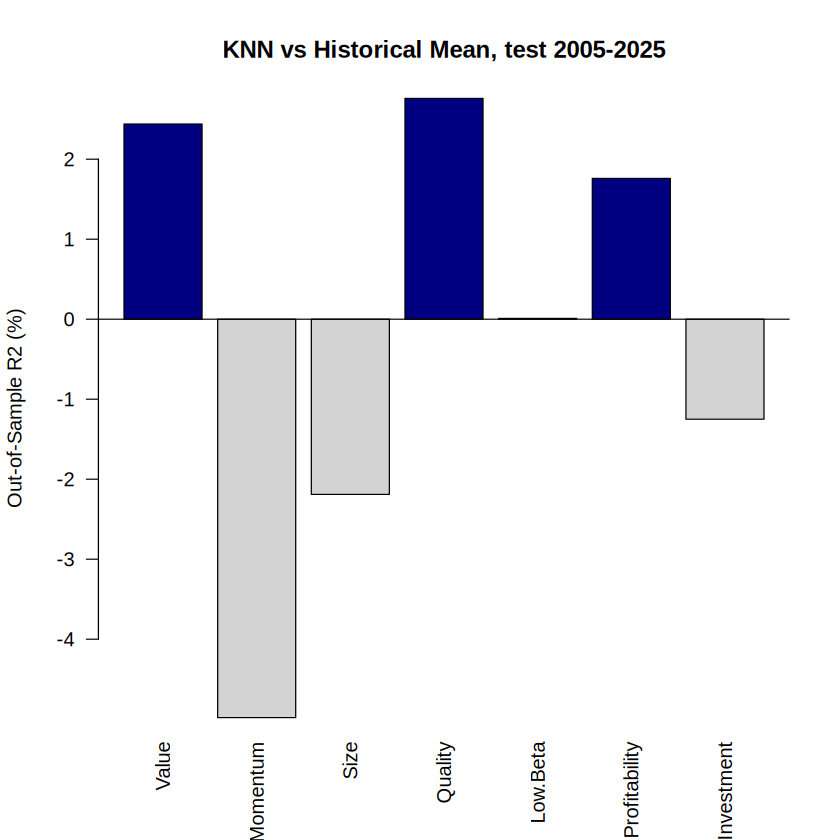

In [ ]:
barplot(results$oos_r2_pct, names.arg = results$factor, las = 2,
        col = ifelse(results$oos_r2_pct > 0, "navy", "lightgrey"),
        ylab = "Out-of-Sample R2 (%)", main = "KNN vs Historical Mean, test 2005-2025")
abline(h = 0)

In [ ]:
if (!requireNamespace("pROC", quietly = TRUE))
    install.packages("pROC")
library(pROC)

Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var




In [ ]:
up <- factor(ifelse(tst$ret > 0, "Up", "Down"), levels = c("Down","Up"))
table(up)

up
Down   Up 
 147  105 

Setting levels: control = Down, case = Up

Setting direction: controls < cases



Area under the curve: 0.5313

95% CI: 0.4571-0.6054 (DeLong)

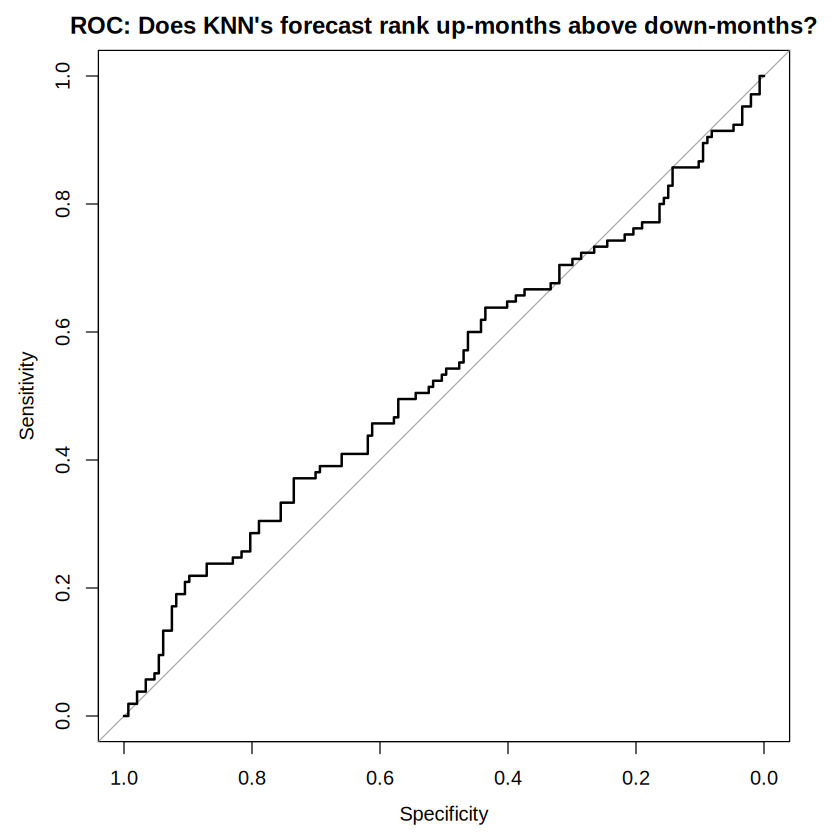

In [ ]:
knn_roc <- roc(up, pred)
plot(knn_roc, main = "ROC: Does KNN's forecast rank up-months above down-months?")
auc(knn_roc)
ci.auc(knn_roc)